# 03 - Portfolio backtest, costs and sensitivity

Trades go through the project-02 backtester (signal at close, fill next open).  Gross = no costs, borrow or interest; net = all of them.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TAB, FIG = ROOT / "results" / "tables", ROOT / "results" / "figures"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("SYNTHETIC results demonstrate software behaviour; they are not market evidence.")

SYNTHETIC results demonstrate software behaviour; they are not market evidence.


In [2]:
from pairs.experiments import build_context, run, summary
from pairs import analysis as A
ctx = build_context(ROOT, 'synthetic', 'fast')
plans = ctx.plans('test')[:2]  # two cohorts only, to keep this quick
rows = {}
for sc, bps in [('flat', 0.0), ('flat', 20.0)]:
    res, s = run(ctx, 'test', plans=plans, scenario=sc, flat_bps=bps)
    rows[f'{bps:g}bps'] = summary(ctx, res, s, sc)
pd.DataFrame(rows).loc[['sharpe','cagr','total_trading_costs','completed_pair_trades']]

,0bps,20bps
sharpe,0.687365,0.485279
cagr,0.02274,0.021798
total_trading_costs,0.0,4930.005198
completed_pair_trades,8,8


In [3]:
pnl, rec = A.attribute_pairs(res, s, ctx.market_data('test'))
print('max |engine - pairs - financing|:', float(rec.unattributed.abs().max()))

max |engine - pairs - financing|: 2.0227162167429924e-09


In [4]:
for f in ['syn_10_portfolio_metrics.csv', 'syn_12_cost_sensitivity.csv', 'syn_14_hedge_method_comparison.csv', 'mkt_10_portfolio_metrics.csv', 'mkt_14_hedge_method_comparison.csv']:
    p = TAB / f
    if p.exists():
        print(f); display(pd.read_csv(p).head(12))

syn_10_portfolio_metrics.csv


,Unnamed: 0,gross,net
0,start,2017-01-02,2017-01-02
1,end,2021-12-31,2021-12-31
2,cagr,0.03811635668792057,0.05399622765132084
3,ann_vol,0.017946219867828864,0.017917657773311585
4,sharpe,2.0935607167529766,1.8674607387820332
5,sortino,3.433083706885524,3.0117069641878818
6,max_drawdown,0.014111301688797262,0.010376951800792233
7,turnover_annual,3.4117630685311275,3.4110964524491045
8,avg_gross_exposure,0.12051456170607282,0.12047533029187486
9,avg_net_exposure,-0.004550050782286742,-0.004561240283548368


syn_12_cost_sensitivity.csv


,start,end,cagr,ann_vol,sharpe,sortino,max_drawdown,turnover_annual,avg_gross_exposure,avg_net_exposure,time_invested,commissions,spread_costs,slippage_costs,total_trading_costs,interest,borrow_fees,market_beta_raw,share_abs_z_ge_entry,z_sd,completed_pair_trades,avg_holding_sessions,leg_failures,breakdown_exits,stop_loss_exits,rehedges,sharpe_rf,backstop_bound,one_way_bps_per_leg
0,2017-01-02,2021-12-31,0.056881,0.017933,2.018403,3.289731,0.009809,3.411376,0.120492,-0.004543,0.567816,0.000000,0.0,0.0,0.000000,111679.792815,1892.777750,-0.006413,0.091697,1.240738,158,9.158228,0,3,0,0,0.02,False,0
1,2017-01-02,2021-12-31,0.053272,0.017923,1.828536,2.940502,0.010498,3.411574,0.120502,-0.004530,0.567816,20903.744799,0.0,0.0,20903.744799,110700.648950,1874.663206,-0.006380,0.091697,1.240738,158,9.158228,0,3,0,0,0.02,False,5
2,2017-01-02,2021-12-31,0.049677,0.017919,1.637974,2.599221,0.011232,3.411628,0.120512,-0.004528,0.567816,41427.273377,0.0,0.0,41427.273377,109736.568984,1857.027429,-0.006334,0.091697,1.240738,158,9.158228,0,3,0,0,0.02,False,10
3,2017-01-02,2021-12-31,0.042548,0.017961,1.254514,1.938528,0.012600,3.412179,0.120543,-0.004552,0.567816,81369.994551,0.0,0.0,81369.994551,107839.298817,1822.875248,-0.006309,0.091697,1.240738,158,9.158228,0,3,0,0,0.02,False,20


syn_14_hedge_method_comparison.csv


,start,end,cagr,ann_vol,sharpe,sortino,max_drawdown,turnover_annual,avg_gross_exposure,avg_net_exposure,time_invested,commissions,spread_costs,slippage_costs,total_trading_costs,interest,borrow_fees,market_beta_raw,share_abs_z_ge_entry,z_sd,completed_pair_trades,avg_holding_sessions,leg_failures,breakdown_exits,stop_loss_exits,rehedges,sharpe_rf,backstop_bound,method,scenario
0,2017-01-02,2021-12-31,0.053996,0.017918,1.867461,3.011707,0.010377,3.411096,0.120475,-0.004561,0.567816,4187.755285,8375.524193,4187.762097,16751.041575,110896.859005,1878.317033,-0.006409,0.091697,1.240738,158,9.158228,0,3,0,0,0.02,False,static_ols,net
1,2017-01-02,2021-12-31,0.038116,0.017946,2.093561,3.433084,0.014111,3.411763,0.120515,-0.004550,0.567816,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.006426,0.091697,1.240738,158,9.158228,0,3,0,0,0.00,False,static_ols,gross
2,2017-01-02,2021-12-31,0.042336,0.013926,1.597942,2.629918,0.009847,2.280555,0.078541,-0.000401,0.441379,2672.676709,5345.362293,2672.681146,10690.720149,108268.155162,1125.474716,-0.002294,0.123290,1.286454,98,9.418367,0,3,11,187,0.02,False,rolling_ols,net
3,2017-01-02,2021-12-31,0.025237,0.013952,1.793450,3.008852,0.011305,2.281629,0.078588,-0.000390,0.441379,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.002240,0.123290,1.286454,98,9.418367,0,3,11,187,0.00,False,rolling_ols,gross
4,2017-01-02,2021-12-31,0.023174,0.003718,0.996869,1.812709,0.002698,0.166141,0.005584,0.000182,0.044444,187.607530,375.216354,187.608177,750.432062,107760.475786,72.687997,0.000748,0.002119,0.639785,7,8.571429,0,0,0,0,0.02,False,kalman,net
5,2017-01-02,2021-12-31,0.003789,0.003633,1.042788,1.935511,0.003226,0.166185,0.005586,0.000182,0.044444,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000771,0.002119,0.639785,7,8.571429,0,0,0,0,0.00,False,kalman,gross


mkt_10_portfolio_metrics.csv


,Unnamed: 0,gross,net
0,start,2018-01-02,2018-01-02
1,end,2023-12-29,2023-12-29
2,cagr,-0.001930007868529482,0.01721846564881724
3,ann_vol,0.006174845160014579,0.006229126278782713
4,sharpe,-0.3097721502609886,-0.47485407968520293
5,sortino,-0.3923273081453751,-0.5934795501847119
6,max_drawdown,0.020511270843870943,0.012594014331126502
7,turnover_annual,0.7872238357278676,0.7869984073337978
8,avg_gross_exposure,0.033685716318127286,0.03367217483370102
9,avg_net_exposure,-0.00016866433081446207,-0.00016940698781545222


mkt_14_hedge_method_comparison.csv


,start,end,cagr,ann_vol,sharpe,sortino,max_drawdown,turnover_annual,avg_gross_exposure,avg_net_exposure,time_invested,commissions,spread_costs,slippage_costs,total_trading_costs,interest,borrow_fees,market_beta_raw,share_abs_z_ge_entry,z_sd,completed_pair_trades,avg_holding_sessions,leg_failures,breakdown_exits,stop_loss_exits,rehedges,sharpe_rf,backstop_bound,method,scenario
0,2018-01-02,2023-12-29,0.017218,0.006229,-0.474854,-0.593480,0.012594,0.786998,0.033672,-0.000169,0.174288,1015.443616,2030.886466,1015.443233,4061.773316,127148.610393,538.989770,0.002583,0.117091,1.319011,32,11.1875,0,4,0,0,0.02,False,static_ols,net
1,2018-01-02,2023-12-29,-0.001930,0.006175,-0.309772,-0.392327,0.020511,0.787224,0.033686,-0.000169,0.174288,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.002694,0.117091,1.319011,32,11.1875,0,4,0,0,0.00,False,static_ols,gross
2,2018-01-02,2023-12-29,0.018841,0.004709,-0.289854,-0.390983,0.007754,0.635809,0.027492,0.001652,0.137177,822.217505,1644.434789,822.217394,3288.869688,128002.528449,425.895898,0.000060,0.192000,1.585982,25,12.4400,0,3,3,32,0.02,False,rolling_ols,net
3,2018-01-02,2023-12-29,-0.000514,0.004623,-0.108882,-0.149939,0.014941,0.635995,0.027503,0.001652,0.137177,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000123,0.192000,1.585982,25,12.4400,0,3,3,32,0.00,False,rolling_ols,gross
4,2018-01-02,2023-12-29,0.018503,0.003210,-0.540406,-0.544184,0.007135,0.074528,0.001191,0.000020,0.007952,96.382392,192.764142,96.382071,385.528604,129440.610437,17.481041,-0.001828,0.022545,0.695321,3,4.0000,0,1,1,0,0.02,False,kalman,net
5,2018-01-02,2023-12-29,-0.001639,0.003084,-0.530273,-0.534376,0.010502,0.074518,0.001190,0.000020,0.007952,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.001739,0.022545,0.695321,3,4.0000,0,1,1,0,0.00,False,kalman,gross


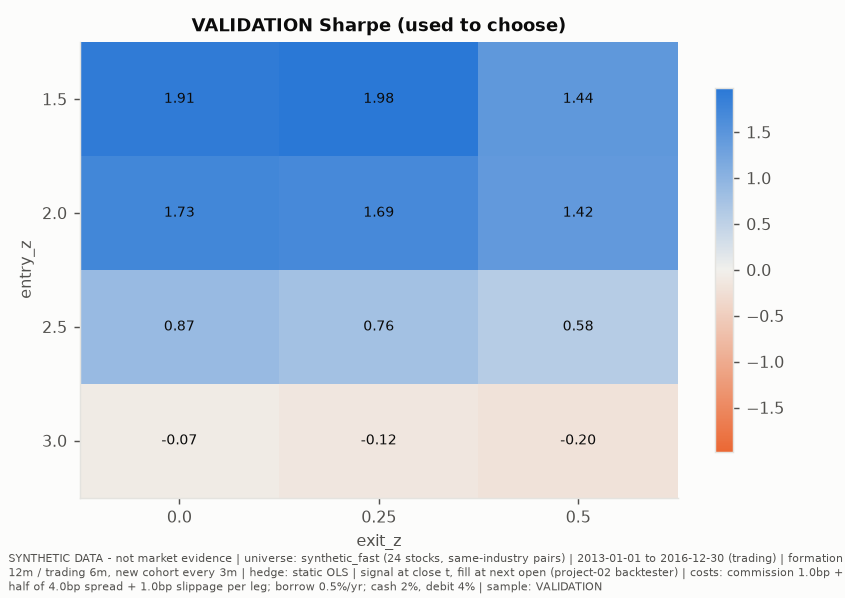

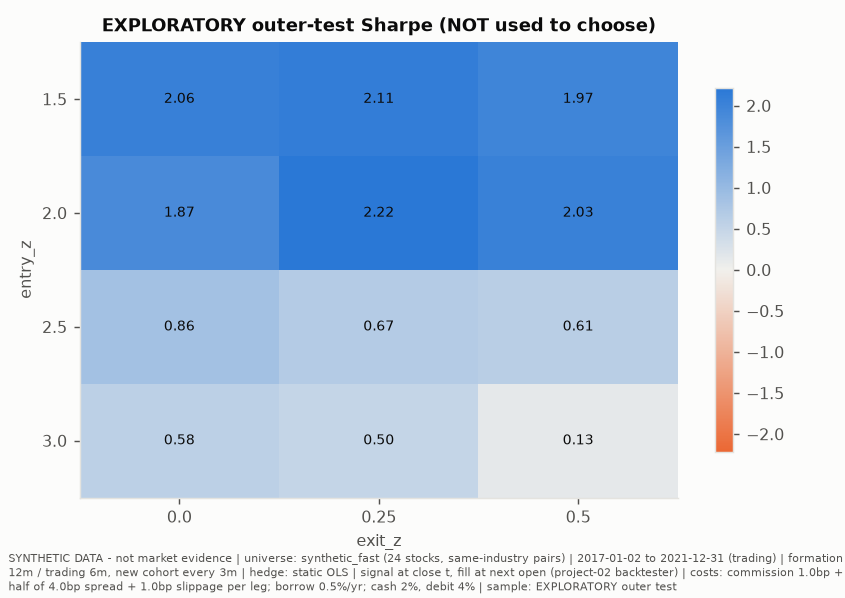

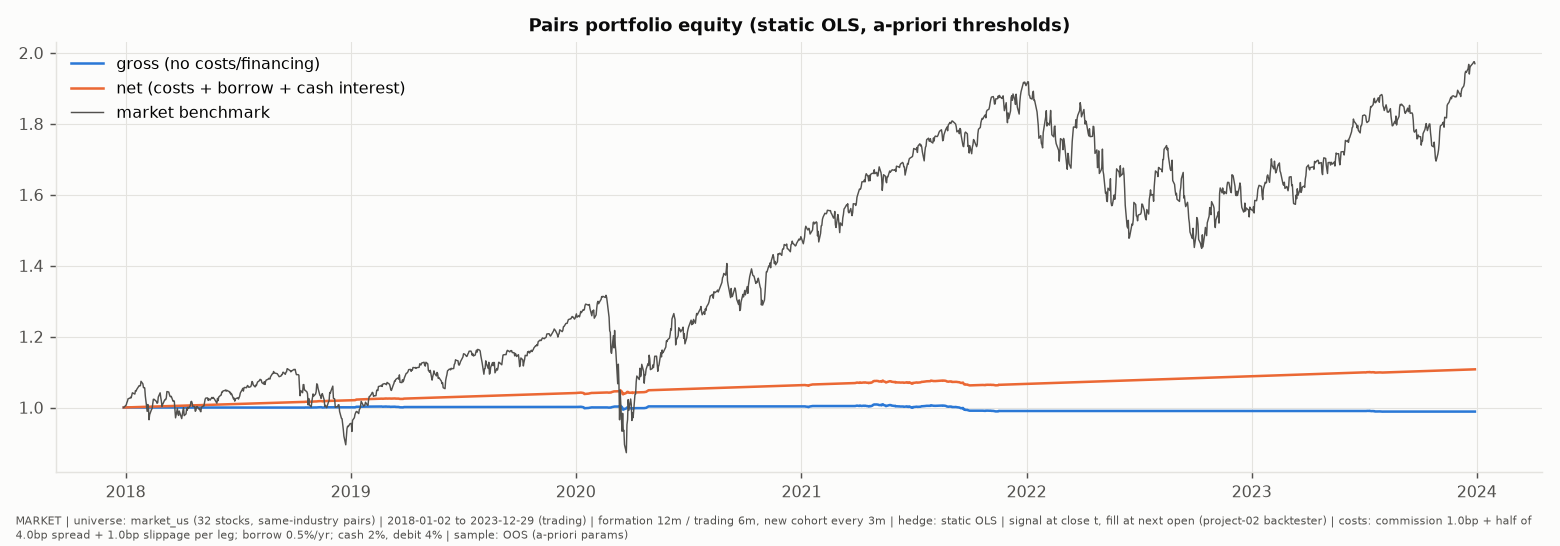

In [5]:
for f in ['syn_13_threshold_heatmap_validation.png', 'syn_13b_threshold_heatmap_EXPLORATORY_test.png', 'mkt_08_equity_gross_net.png']:
    display(Image(FIG / f))